In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv("../data/raw/ai4i2020.csv")

In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.shape

(10000, 14)

In [6]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [8]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


EDA — Step 1: Understand the Target


In [9]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [10]:
df["Machine failure"].value_counts(normalize=True)*100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Step 2 — Visualize Failure Distribution


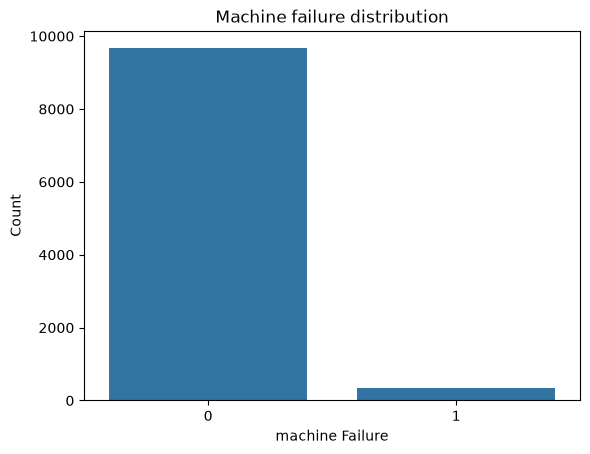

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df,x="Machine failure")

plt.title("Machine failure distribution")
plt.xlabel("machine Failure")
plt.ylabel("Count")
plt.show()

Step 3 — Look at Failure Modes


Remember these columns?
TWF
HDF
PWF
OSF
RNF
These tell us about different failure modes in the dataset.

In [12]:
failure_modes=["TWF","HDF","PWF","OSF","RNF"]
df[failure_modes].sum().sort_values(ascending=False)

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

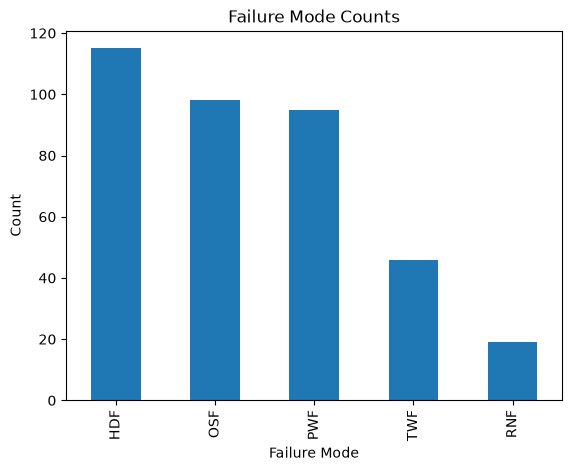

In [13]:
df[failure_modes].sum().sort_values(ascending=False).plot(
    kind="bar"
)

plt.title("Failure Mode Counts")
plt.xlabel("Failure Mode")
plt.ylabel("Count")
plt.show()

Step 4 — Check Numerical Feature Distributions


In [14]:
numeric_features=[
    "Air Temperature [K]",
    "Process Temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"

]

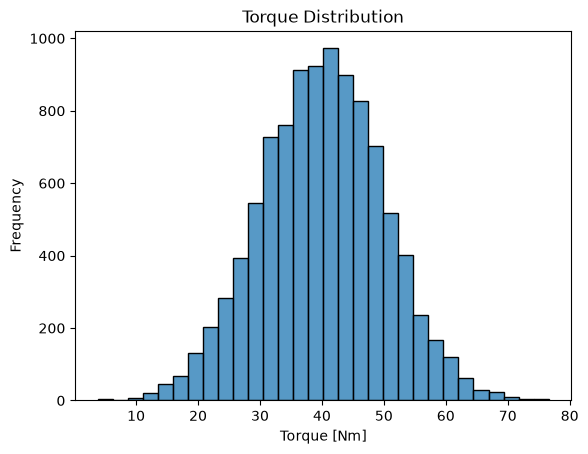

In [15]:
sns.histplot(data=df, x="Torque [Nm]", bins=30)

plt.title("Torque Distribution")
plt.xlabel("Torque [Nm]")
plt.ylabel("Frequency")
plt.show()

Next EDA: Compare Failure vs No Failure


This is MUCH more useful than just looking at distributions.


We want to answer:
Do machines that fail have different sensor readings from machines that don't fail?
Start with Torque.

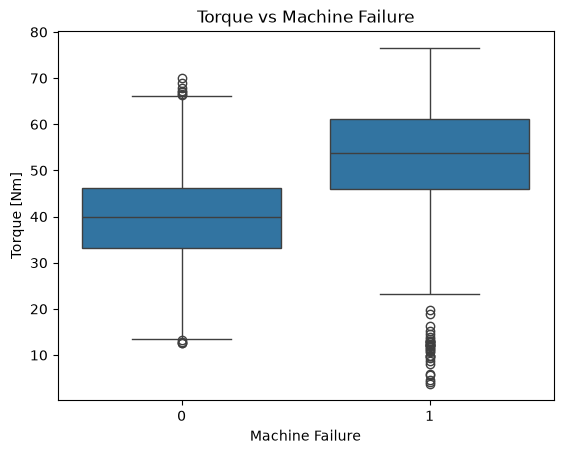

In [16]:
sns.boxplot(data=df, x="Machine failure",y="Torque [Nm]")

plt.title("Torque vs Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Torque [Nm]")
plt.show()

### Torque vs Machine Failure

- Non-failed machines have a median torque of approximately 40 Nm.
- Failed machines have a higher median torque of approximately 54 Nm.
- Failed machines show several low-torque potential outliers.
- Torque appears to have a relationship with machine failure.
- However, there is still overlap between the two groups, so torque alone is not sufficient for prediction.
- Potential outliers are retained for now because extreme sensor values may represent genuine machine conditions.

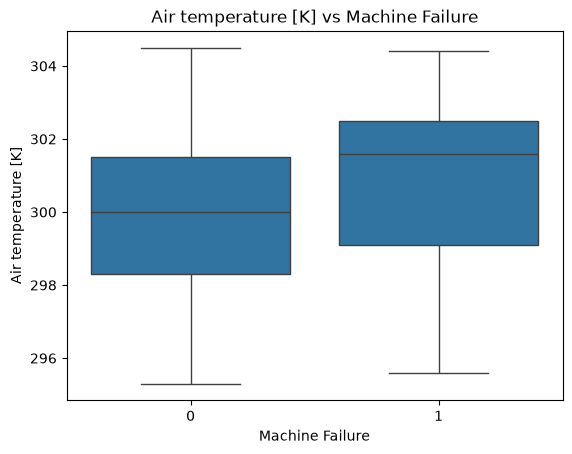

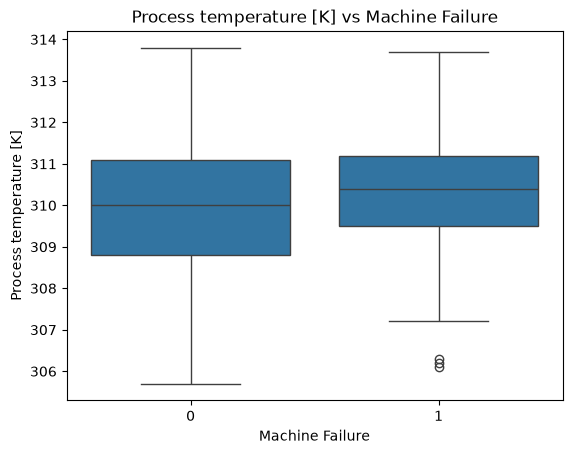

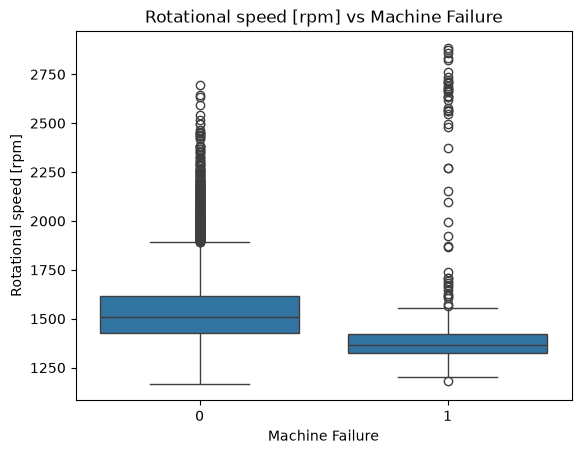

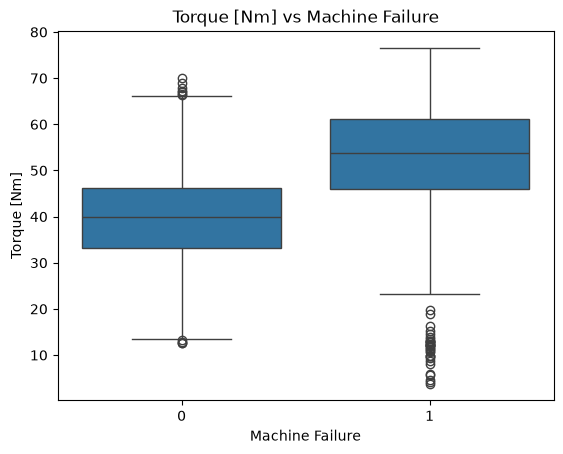

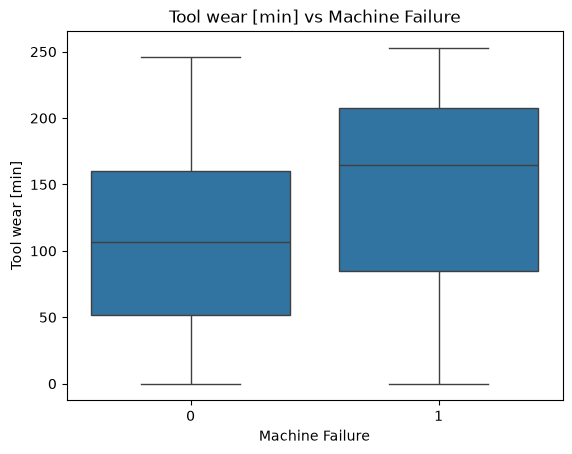

In [17]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for feature in numeric_features:
    sns.boxplot(data=df, x="Machine failure", y=feature)
    plt.title(f"{feature} vs Machine Failure")
    plt.xlabel("Machine Failure")
    plt.ylabel(feature)
    plt.show()

### Numerical Features vs Machine Failure

- Air temperature is slightly higher for failed machines, but the distributions overlap considerably.
- Process temperature shows only a small difference between failed and non-failed machines.
- Failed machines generally have lower rotational speed.
- Failed machines have substantially higher torque than non-failed machines.
- Failed machines generally show higher tool wear.
- Torque and tool wear show the clearest differences between failure and non-failure groups.
- Potential outliers are visible in several features and are retained for now because they may represent genuine machine conditions.
- These observations show associations, not causation.

### Next EDA step: Correlation

Now we want to answer another question:
How strongly are our numerical features related to each other and to machine failure?

In [18]:
corr=df[numeric_features+["Machine failure"]].corr()

corr

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
Machine failure,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


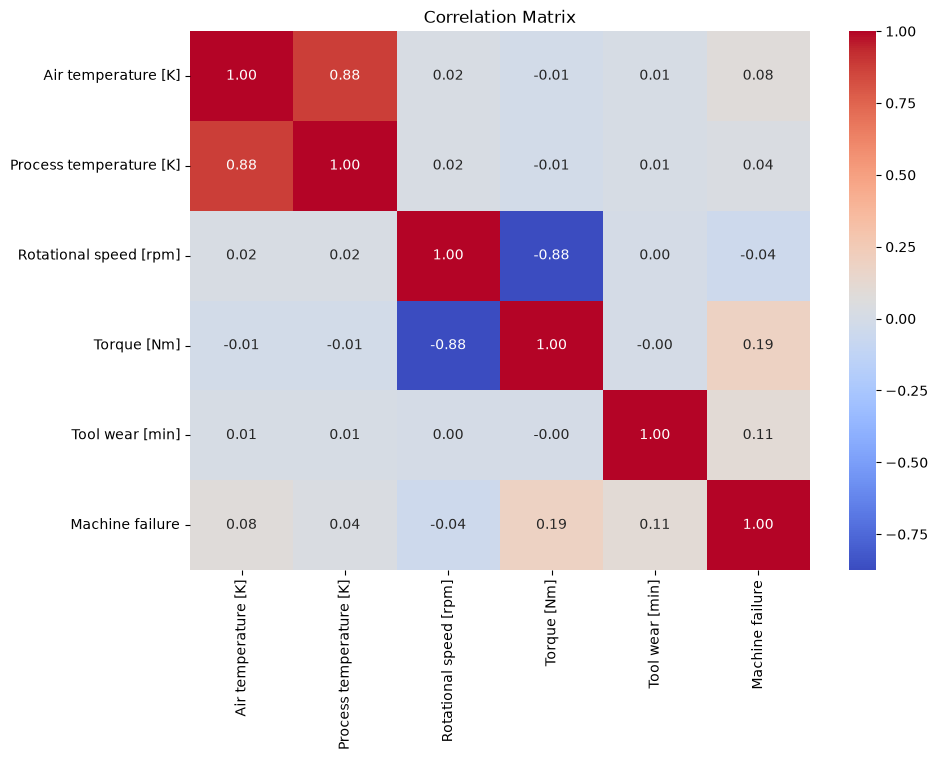

In [19]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

### Correlation Analysis

- Air temperature and process temperature have a strong positive correlation (r ≈ 0.88).
- Rotational speed and torque have a strong negative correlation (r ≈ -0.88).
- Correlations with machine failure are relatively small in magnitude.
- Torque has the highest linear correlation with machine failure (r ≈ 0.19), followed by tool wear (r ≈ 0.11).
- Low correlation with machine failure does not necessarily mean a feature is unimportant because correlation mainly captures linear relationships.
- Feature usefulness will ultimately be evaluated using machine learning models and validation performance.

### Next EDA — Machine Type vs Failure

We want to answer:
Does machine type have a different failure rate?

In [20]:
## Step 1 — Count machines by type

df["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [21]:
## Step 2 — Failure count by type
pd.crosstab(df["Type"],df["Machine failure"])

Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


In [22]:
## Step 3 — Failure rate by type
failure_rate = pd.crosstab(
    df["Type"],
    df["Machine failure"],
    normalize="index"
) * 100

failure_rate


Machine failure,0,1
Type,,
H,97.906281,2.093719
L,96.083333,3.916667
M,97.230564,2.769436


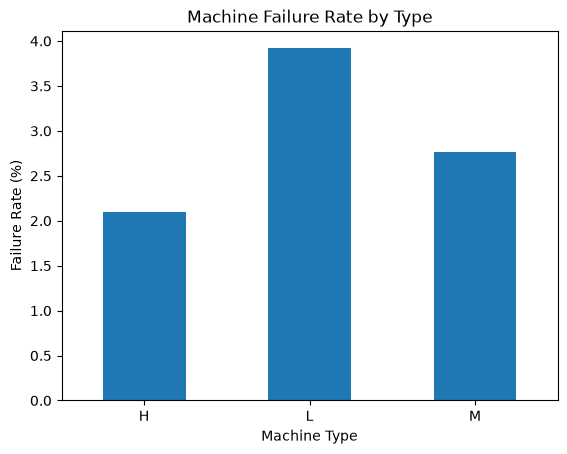

In [23]:
failure_rate[1].plot(kind="bar")

plt.title("Machine Failure Rate by Type")
plt.xlabel("Machine Type")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Machine Type vs Machine Failure

- H-type machines: 2.09% failure rate
- L-type machines: 3.92% failure rate
- M-type machines: 2.77% failure rate
- L-type machines have the highest observed failure rate.
- Machine type shows some association with machine failure, but the difference in failure rates is not extremely large.
- Failure rate is more informative than raw failure count because the number of machines differs across types.

### Next: Failure-mode analysis

In [24]:
df[failure_modes].corr()

,TWF,HDF,PWF,OSF,RNF
TWF,1.000000,-0.007332,0.008577,0.038243,0.030970
HDF,-0.007332,1.000000,0.018443,0.046396,-0.004706
PWF,0.008577,0.018443,1.000000,0.115836,-0.004273
OSF,0.038243,0.046396,0.115836,1.000000,-0.004341
RNF,0.030970,-0.004706,-0.004273,-0.004341,1.000000


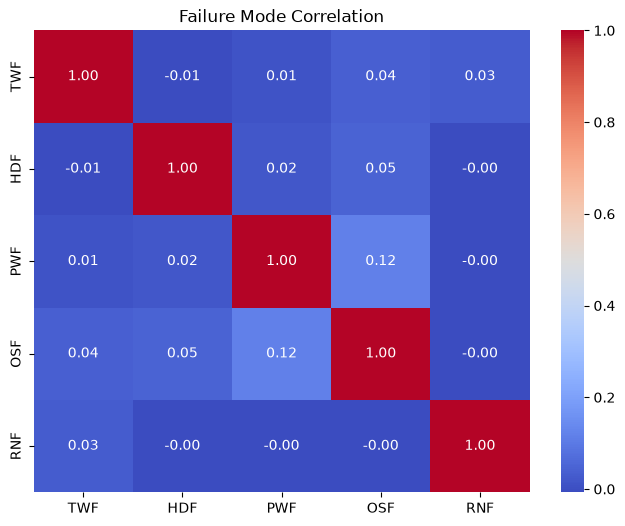

In [25]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[failure_modes].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Failure Mode Correlation")
plt.show()

### Failure Mode Analysis

- Correlations between individual failure-mode indicators are generally close to zero.
- PWF and OSF have the highest correlation (~0.12), but this is still a weak association.
- The failure-mode indicators do not show strong pairwise linear relationships.
- HDF is the most frequently observed failure mode, followed by OSF and PWF.
- These failure-mode columns will be used for failure analysis and dashboard insights rather than as input features for the initial prediction model.

# EDA Summary

## Dataset
- 10,000 observations and 14 columns.
- No missing values are present.
- Target variable: `Machine failure`.

## Target Distribution
- No failure: 9661 (96.61%)
- Failure: 339 (3.39%)
- The target is highly imbalanced.

## Numerical Features
- Air temperature shows a small difference between failed and non-failed machines.
- Process temperature shows a very small difference.
- Failed machines generally have lower rotational speed.
- Failed machines have noticeably higher torque.
- Failed machines generally have higher tool wear.
- Potential outliers are present in several numerical features.
- Outliers are retained for now because extreme sensor values may represent genuine machine conditions.

## Correlation Analysis
- Air temperature and process temperature have a strong positive correlation (~0.88).
- Rotational speed and torque have a strong negative correlation (~-0.88).
- Correlations with machine failure are relatively small.
- Torque has the highest linear correlation with machine failure (~0.19).
- Tool wear has the next highest (~0.11).
- Low correlation does not necessarily mean a feature is unimportant because correlation mainly measures linear relationships.

## Machine Type
- H-type failure rate: ~2.09%
- L-type failure rate: ~3.92%
- M-type failure rate: ~2.77%
- L-type machines have the highest observed failure rate.
- Machine type shows some association with failure.

## Failure Modes
- HDF: 115
- OSF: 98
- PWF: 95
- TWF: 46
- RNF: 19
- Failure-mode indicators have generally weak pairwise correlations.
- These columns will be used for failure analysis rather than the initial prediction model.

## Initial Feature Selection

### Features for the initial model
- `Type`
- `Air temperature [K]`
- `Process temperature [K]`
- `Rotational speed [rpm]`
- `Torque [Nm]`
- `Tool wear [min]`

### Columns excluded from the initial model
- `UDI` → identifier
- `Product ID` → identifier
- `TWF`, `HDF`, `PWF`, `OSF`, `RNF` → failure-mode indicators; potential target leakage depending on when they become available

## Conclusion
The dataset is highly imbalanced. Torque, tool wear, and rotational speed show noticeable distributional differences between failed and non-failed machines. Machine type also shows some variation in failure rate. These observations will guide preprocessing and model development, but final feature usefulness will be determined through model validation.